In [ ]:
import torch
import torchvision
from torchvision.transforms import v2
import matplotlib.pyplot as plt
import numpy as np
import torch.nn as nn
import torch.nn.functional as F
import math


# Dataset

In [ ]:
transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

batch_size = 128

trainset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size, shuffle=True, num_workers=2)

testset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size, shuffle=False, num_workers=2)

classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

In [ ]:
print("Training images:", len(trainset))
print("Testing images:", len(testset))

[[[0.5        0.5        0.5        ... 0.5        0.5        0.5       ]
  [0.5        0.5        0.5        ... 0.5        0.5        0.5       ]
  [0.5        0.5        0.38823533 ... 0.17647058 0.5        0.5       ]
  ...
  [0.5        0.5        0.72156864 ... 0.5294118  0.5        0.5       ]
  [0.5        0.5        0.5        ... 0.5        0.5        0.5       ]
  [0.5        0.5        0.5        ... 0.5        0.5        0.5       ]]

 [[0.5        0.5        0.5        ... 0.5        0.5        0.5       ]
  [0.5        0.5        0.5        ... 0.5        0.5        0.5       ]
  [0.5        0.5        0.43921572 ... 0.20000002 0.5        0.5       ]
  ...
  [0.5        0.5        0.7058824  ... 0.44705886 0.5        0.5       ]
  [0.5        0.5        0.5        ... 0.5        0.5        0.5       ]
  [0.5        0.5        0.5        ... 0.5        0.5        0.5       ]]

 [[0.5        0.5        0.5        ... 0.5        0.5        0.5       ]
  [0.5        0.5     

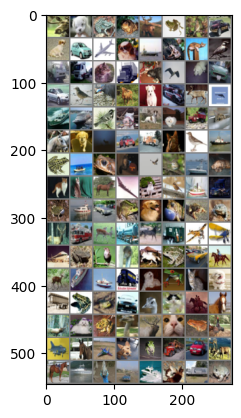

deer  dog   frog  frog  deer  frog  bird  car   dog   car   plane dog   ship  frog  cat   bird  truck truck cat   truck dog   bird  dog   car   car   bird  bird  deer  dog   car   deer  plane ship  ship  bird  horse dog   dog   truck cat   horse dog   deer  car   truck cat   bird  ship  frog  ship  frog  cat   bird  bird  ship  dog   cat   cat   horse plane cat   bird  ship  truck frog  ship  car   frog  dog   frog  frog  frog  deer  truck deer  truck horse truck plane plane plane frog  bird  bird  horse frog  car   horse deer  ship  ship  truck dog   frog  cat   dog   truck frog  frog  car   bird  cat   horse horse deer  dog   frog  bird  deer  cat   frog  bird  plane horse plane dog   frog  truck car   deer  horse ship  bird  car   ship  cat   truck frog 


In [24]:
def imshow(img):
    img = img / 2 + 0.5
    # normalize: 
    npimg = img.numpy()
    print(npimg)
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()
dataiter = iter(trainloader)
images, labels = next(dataiter)
imshow(torchvision.utils.make_grid(images))
print(' '.join(f'{classes[labels[j]]:5s}' for j in range(batch_size)))

# MLP Configuration

In [25]:
SEED = 42
EPOCHS = 10
LEARNING_RATE = 0.001

torch.manual_seed(SEED)
np.random.seed(SEED)

# CNN Model

In [26]:
class MLPClassifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.flatten = nn.Flatten()

        self.fc1 = nn.Linear(3 * 32 * 32, 512)
        self.relu1 = nn.ReLU()

        self.fc2 = nn.Linear(512, 256)
        self.relu2 = nn.ReLU()

        self.fc3 = nn.Linear(256, 10)

    def forward(self, x):
        x = self.flatten(x)    # [B, 3, 32, 32] -> [B, 3072]

        x = self.fc1(x)        # [B, 3072] -> [B, 512]
        x = self.relu1(x)

        x = self.fc2(x)        # [B, 512] -> [B, 256]
        x = self.relu2(x)

        x = self.fc3(x)        # [B, 256] -> [B, 10]

        # Return logits, not softmax probabilities.
        return x

# Define a Loss function and optimizer

In [27]:
import torch.optim as optim

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = MLPClassifier().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=LEARNING_RATE, momentum=0.9)

# Training & Analysis

## Training

In [ ]:

# Configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)
# Information before training
print("Device:", device)
print("Batch size:", batch_size)
print("Learning rate:", LEARNING_RATE)
print("\nModel architecture:")
print(model)
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)
print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)

history = {
    "epoch": [],
    "train_loss": [],
    "test_loss": [],
    "train_accuracy": [],
    "test_accuracy": [],
    "learning_rate": []
}

# Training and Evaluation
for epoch in range(EPOCHS):

    # Training phase
    model.train()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for inputs, labels in trainloader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        # Reset gradient
        optimizer.zero_grad()

        # Forward propagation
        outputs = model(inputs)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        # Accumulate statistics
        batch_size = labels.size(0)
        train_loss_sum += loss.item() * batch_size

        _, predicted = torch.max(outputs, dim=1)
        train_total += batch_size
        train_correct += (predicted == labels).sum().item()

    train_loss = train_loss_sum / train_total
    train_accuracy = 100.0 * train_correct / train_total

    # Testing phase
    model.eval()

    test_loss_sum = 0.0
    test_correct = 0
    test_total = 0

    with torch.no_grad():
        for inputs, labels in testloader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            # Forward propagation only
            outputs = model(inputs)

            # Calculate test loss
            loss = criterion(outputs, labels)

            batch_size = labels.size(0)
            test_loss_sum += loss.item() * batch_size

            _, predicted = torch.max(outputs, dim=1)
            test_total += batch_size
            test_correct += (predicted == labels).sum().item()

    test_loss = test_loss_sum / test_total
    test_accuracy = 100.0 * test_correct / test_total

    # Record metrics
    current_lr = optimizer.param_groups[0]["lr"]

    history["epoch"].append(epoch + 1)
    history["train_loss"].append(train_loss)
    history["test_loss"].append(test_loss)
    history["train_accuracy"].append(train_accuracy)
    history["test_accuracy"].append(test_accuracy)
    history["learning_rate"].append(current_lr)

    # Print results
    print(
        f"Epoch [{epoch + 1:02d}/{EPOCHS:02d}] | "
        f"LR: {current_lr:.6f} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Test Loss: {test_loss:.4f} | "
        f"Train Acc: {train_accuracy:.2f}% | "
        f"Test Acc: {test_accuracy:.2f}%"
    )


Device: cuda
Batch size: 128
Learning rate: 0.001

Model architecture:
MLPClassifier(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=3072, out_features=512, bias=True)
  (relu1): ReLU()
  (fc2): Linear(in_features=512, out_features=256, bias=True)
  (relu2): ReLU()
  (fc3): Linear(in_features=256, out_features=10, bias=True)
)
Total parameters: 1707274
Trainable parameters: 1707274
Epoch [01/10] | LR: 0.001000 | Train Loss: 2.1698 | Test Loss: 2.0209 | Train Acc: 24.48% | Test Acc: 29.42%
Epoch [02/10] | LR: 0.001000 | Train Loss: 1.9283 | Test Loss: 1.8450 | Train Acc: 32.24% | Test Acc: 35.01%
Epoch [03/10] | LR: 0.001000 | Train Loss: 1.7961 | Test Loss: 1.7461 | Train Acc: 36.70% | Test Acc: 38.48%
Epoch [04/10] | LR: 0.001000 | Train Loss: 1.7139 | Test Loss: 1.6809 | Train Acc: 39.51% | Test Acc: 40.95%
Epoch [05/10] | LR: 0.001000 | Train Loss: 1.6550 | Test Loss: 1.6264 | Train Acc: 41.78% | Test Acc: 43.28%
Epoch [06/10] | LR: 0.001000 | Train Loss: 

## Save Model

In [29]:
PATH = './cifar_mlp.pt'
torch.save(model.state_dict(), PATH)

# Testing

[[[0.5        0.5        0.5        ... 0.5        0.5        0.5       ]
  [0.5        0.5        0.5        ... 0.5        0.5        0.5       ]
  [0.5        0.5        0.61960787 ... 0.08235294 0.5        0.5       ]
  ...
  [0.5        0.5        0.45882356 ... 0.00392157 0.5        0.5       ]
  [0.5        0.5        0.5        ... 0.5        0.5        0.5       ]
  [0.5        0.5        0.5        ... 0.5        0.5        0.5       ]]

 [[0.5        0.5        0.5        ... 0.5        0.5        0.5       ]
  [0.5        0.5        0.5        ... 0.5        0.5        0.5       ]
  [0.5        0.5        0.43921572 ... 0.09803921 0.5        0.5       ]
  ...
  [0.5        0.5        0.45882356 ... 0.00392157 0.5        0.5       ]
  [0.5        0.5        0.5        ... 0.5        0.5        0.5       ]
  [0.5        0.5        0.5        ... 0.5        0.5        0.5       ]]

 [[0.5        0.5        0.5        ... 0.5        0.5        0.5       ]
  [0.5        0.5     

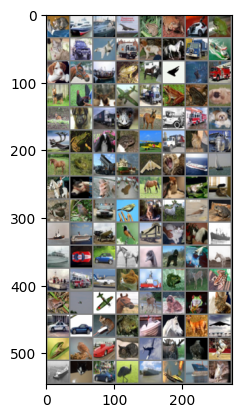

GroundTruth:  cat   ship  ship  plane frog  frog  car   frog  cat   car   plane truck dog   horse truck ship 


In [30]:
dataiter = iter(testloader)
images, labels = next(dataiter)

# print images
imshow(torchvision.utils.make_grid(images))
print('GroundTruth: ', ' '.join(f'{classes[labels[j]]:5s}' for j in range(batch_size)))

In [35]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = model.to(device)
images = images.to(device)

outputs = model(images)

In [36]:
outputs = model(images)

In [37]:
_, predicted = torch.max(outputs, 1)
print('Predicted: ', ' '.join(f'{classes[predicted[j]]:5s}'
                              for j in range(batch_size)))

Predicted:  cat   truck ship  plane deer  frog  cat   frog  dog   car   ship  truck car   horse truck ship 


In [ ]:
correct = 0
total = 0

with torch.no_grad():
    for data in testloader:
        images, labels = data
        images = images.to(device)
        labels = labels.to(device)
        # calculate outputs by running images through the network
        outputs = model(images)
        # the class with the highest energy is what we choose as prediction
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print(f'Accuracy of the network on the 10000 test images: {100 * correct // total} %')

Accuracy of the network on the 10000 test images: 48 %


In [43]:
# prepare to count predictions for each class
correct_pred = {classname: 0 for classname in classes}
total_pred = {classname: 0 for classname in classes}

# again no gradients needed
with torch.no_grad():
    for data in testloader:
        images, labels = data
        images = images.to(device)
        labels = labels.to(device)
        outputs = model(images)
        _, predictions = torch.max(outputs, 1)
        # collect the correct predictions for each class
        for label, prediction in zip(labels, predictions):
            if label == prediction:
                correct_pred[classes[label]] += 1
            total_pred[classes[label]] += 1


# print accuracy for each class
for classname, correct_count in correct_pred.items():
    accuracy = 100 * float(correct_count) / total_pred[classname]
    print(f'Accuracy for class: {classname:5s} is {accuracy:.1f} %')

Accuracy for class: plane is 56.7 %
Accuracy for class: car   is 56.8 %
Accuracy for class: bird  is 28.9 %
Accuracy for class: cat   is 38.6 %
Accuracy for class: deer  is 38.8 %
Accuracy for class: dog   is 36.0 %
Accuracy for class: frog  is 58.2 %
Accuracy for class: horse is 52.7 %
Accuracy for class: ship  is 61.9 %
Accuracy for class: truck is 57.4 %


# Analysis

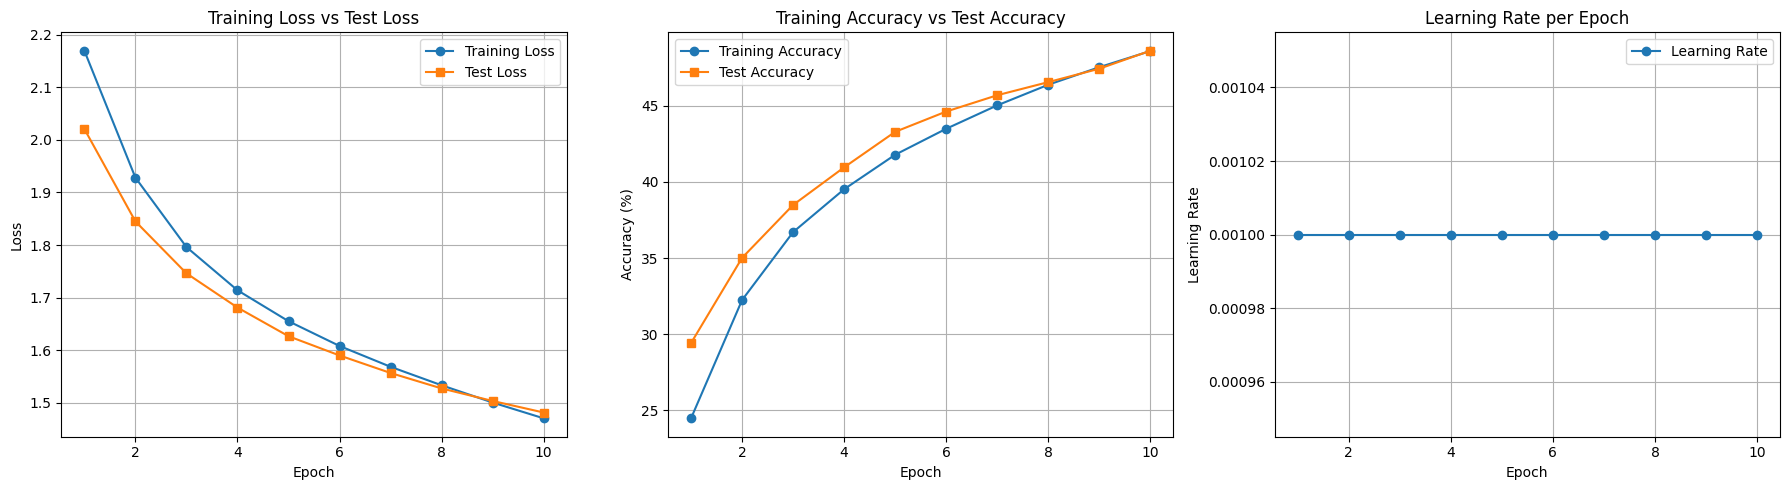

In [44]:
# Plot metrics
epochs = history["epoch"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Training Loss vs Test Loss
axes[0].plot(
    epochs, history["train_loss"],
    marker="o", label="Training Loss"
)
axes[0].plot(
    epochs, history["test_loss"],
    marker="s", label="Test Loss"
)
axes[0].set_title("Training Loss vs Test Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

# Plot 2: Training Accuracy vs Test Accuracy
axes[1].plot(
    epochs, history["train_accuracy"],
    marker="o", label="Training Accuracy"
)
axes[1].plot(
    epochs, history["test_accuracy"],
    marker="s", label="Test Accuracy"
)
axes[1].set_title("Training Accuracy vs Test Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()
axes[1].grid(True)

# Plot 3: Learning Rate
axes[2].plot(
    epochs, history["learning_rate"],
    marker="o", label="Learning Rate"
)
axes[2].set_title("Learning Rate per Epoch")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Learning Rate")
axes[2].legend()
axes[2].grid(True)

plt.tight_layout()
plt.show()

# Confusion Matrix

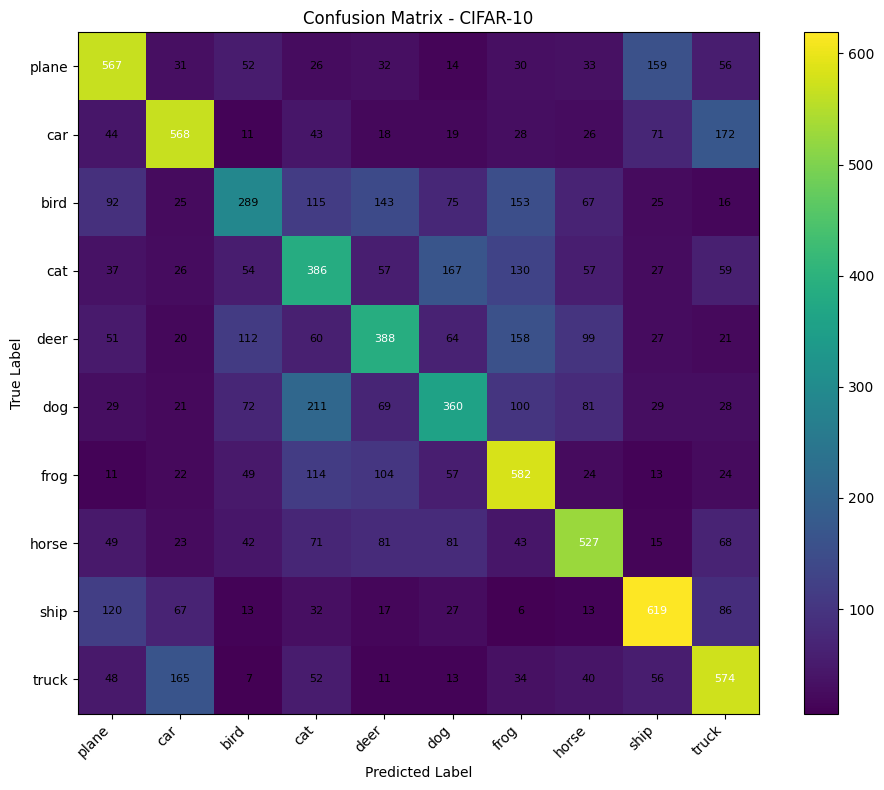

In [45]:
model.eval()

confusion_matrix = torch.zeros(
    10, 10, dtype=torch.int64
)

with torch.no_grad():
    for images, labels in testloader:
        images = images.to(device)
        labels = labels.to(device)

        logits = model(images)
        predictions = logits.argmax(dim=1)

        # Rows = true class; columns = predicted class
        indices = labels * 10 + predictions

        counts = torch.bincount(
            indices.cpu(), minlength=100
        ).reshape(10, 10)

        confusion_matrix += counts

cm = confusion_matrix.numpy()

fig, ax = plt.subplots(figsize=(10, 8))

im = ax.imshow(cm, interpolation="nearest")
ax.set_title("Confusion Matrix - CIFAR-10")
fig.colorbar(im, ax=ax)

ax.set_xticks(range(10))
ax.set_yticks(range(10))
ax.set_xticklabels(classes, rotation=45, ha="right")
ax.set_yticklabels(classes)

ax.set_xlabel("Predicted Label")
ax.set_ylabel("True Label")

threshold = cm.max() / 2

for i in range(10):
    for j in range(10):
        ax.text(
            j, i, str(cm[i, j]),
            ha="center", va="center",
            color="white" if cm[i, j] > threshold else "black",
            fontsize=8
        )

plt.tight_layout()
plt.show()

# Display Misclassified Images

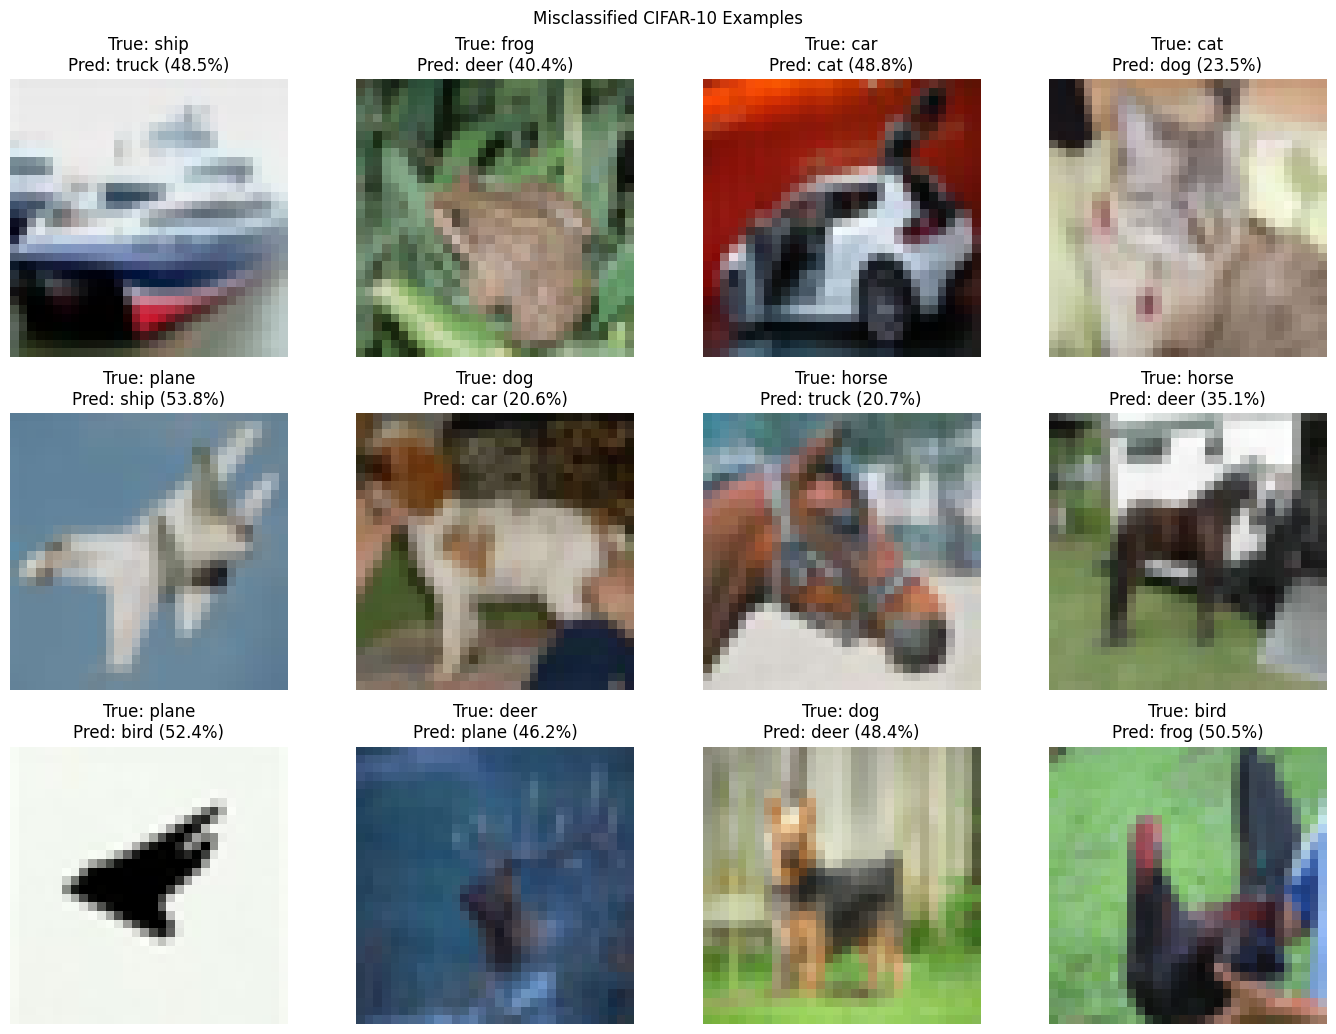


Final results
Train Loss: 1.4701
Test Loss:  1.4812
Train Acc:  48.58%
Test Acc:   48.60%
Number of test errors: 5140


In [46]:
model.eval()

wrong_images = []
wrong_labels = []
wrong_predictions = []
wrong_confidences = []

with torch.no_grad():
    for images, labels in testloader:
        images = images.to(device)
        labels = labels.to(device)

        logits = model(images)
        probabilities = torch.softmax(logits, dim=1)

        predictions = logits.argmax(dim=1)
        wrong_indices = (
            predictions != labels
        ).nonzero(as_tuple=True)[0]

        for idx in wrong_indices:
            wrong_images.append(
                images[idx].cpu()
            )
            wrong_labels.append(
                labels[idx].item()
            )
            wrong_predictions.append(
                predictions[idx].item()
            )
            wrong_confidences.append(
                probabilities[idx, predictions[idx]].item()
            )

            # Keep the first 12 errors
            if len(wrong_images) >= 12:
                break

        if len(wrong_images) >= 12:
            break

if len(wrong_images) == 0:
    print("No misclassified examples found.")
else:
    n = len(wrong_images)
    cols = 4
    rows = (n + cols - 1) // cols

    fig, axes = plt.subplots(
        rows, cols, figsize=(14, 3.5 * rows)
    )
    axes = np.asarray(axes).reshape(-1)

    for i in range(len(axes)):
        axes[i].axis("off")

    for i in range(n):
        # Undo Normalize(mean=0.5, std=0.5)
        image = wrong_images[i] * 0.5 + 0.5
        image = image.permute(1, 2, 0).numpy()
        image = np.clip(image, 0, 1)

        true_name = classes[wrong_labels[i]]
        pred_name = classes[wrong_predictions[i]]
        confidence = wrong_confidences[i] * 100

        axes[i].imshow(image)
        axes[i].set_title(
            f"True: {true_name}\n"
            f"Pred: {pred_name} ({confidence:.1f}%)"
        )

    fig.suptitle("Misclassified CIFAR-10 Examples")
    plt.tight_layout()
    plt.show()

print("\nFinal results")
print(f"Train Loss: {history['train_loss'][-1]:.4f}")
print(f"Test Loss:  {history['test_loss'][-1]:.4f}")
print(f"Train Acc:  {history['train_accuracy'][-1]:.2f}%")
print(f"Test Acc:   {history['test_accuracy'][-1]:.2f}%")
print(f"Number of test errors: {int(cm.sum() - np.trace(cm))}")


# Layer by layer Analysis On One Image

Ground-truth class index: 6

#################################################################
MODEL PARAMETERS
#################################################################

Layer: flatten
Parameter count: 0
Trainable parameters: 0

Layer: fc1
Parameter count: 1573376
Trainable parameters: 1573376
Weight shape: (512, 3072)
Bias shape: (512,)
Weight matrix (first 3 rows, 8 columns):
tensor([[ 0.0138,  0.0150, -0.0042,  0.0166, -0.0040,  0.0036, -0.0088,  0.0106],
        [-0.0045,  0.0016, -0.0048, -0.0177, -0.0019,  0.0088, -0.0021, -0.0089],
        [-0.0143,  0.0034, -0.0036,  0.0136, -0.0179,  0.0006,  0.0080,  0.0023]])
Bias values:
tensor([-4.5375e-03, -1.1734e-02,  2.5573e-03, -1.0750e-04,  8.5314e-03,
         1.4691e-02,  1.7020e-02, -2.9888e-03, -1.0643e-02,  1.3890e-02,
         4.5636e-03, -1.6740e-02, -1.4914e-03,  1.5582e-02, -6.6274e-04,
         1.5975e-02, -7.0332e-03,  5.7072e-03, -3.8593e-03, -1.6994e-02,
        -5.5106e-03,  1.3611e-02, -1.0770e-02, -1.0034e-02

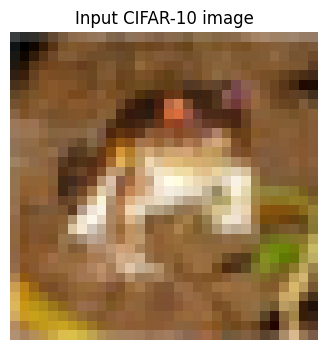


Input
Shape: (1, 3, 32, 32)
Number of elements: 3072
Data type: torch.float32
Min: -1.0
Max: 1.0
Mean: -0.18864886462688446
First 12 values: [-0.5372548699378967, -0.6627451181411743, -0.6078431010246277, -0.46666663885116577, -0.23137247562408447, -0.0666666030883789, 0.09019613265991211, 0.13725495338439941, 0.16862750053405762, 0.16862750053405762, 0.027451038360595703, -0.0196077823638916]

Flatten output
Shape: (1, 3072)
Number of elements: 3072
Data type: torch.float32
Min: -1.0
Max: 1.0
Mean: -0.18864886462688446
First 12 values: [-0.5372548699378967, -0.6627451181411743, -0.6078431010246277, -0.46666663885116577, -0.23137247562408447, -0.0666666030883789, 0.09019613265991211, 0.13725495338439941, 0.16862750053405762, 0.16862750053405762, 0.027451038360595703, -0.0196077823638916]

FC1 before ReLU
Shape: (1, 512)
Number of elements: 512
Data type: torch.float32
Min: -0.6992795467376709
Max: 0.6959954500198364
Mean: 0.006696253549307585
First 12 values: [0.06007019430398941, -0.

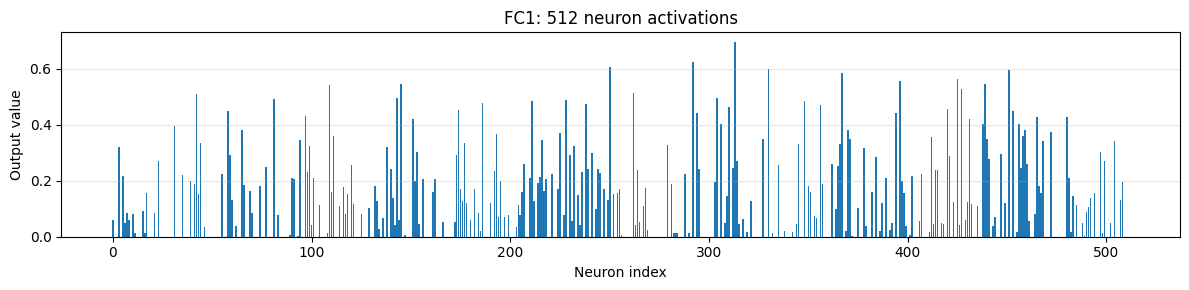


FC2 before ReLU
Shape: (1, 256)
Number of elements: 256
Data type: torch.float32
Min: -0.292091965675354
Max: 0.2654449939727783
Mean: -0.008601229637861252
First 12 values: [-0.03842921182513237, -0.0675019770860672, 0.08742925524711609, -0.0265609472990036, -0.06556981801986694, 0.07840324938297272, 0.20412230491638184, 0.07742463797330856, 0.10802733153104782, -0.12185055017471313, -0.08488030731678009, 0.04977471008896828]

FC2 after ReLU
Shape: (1, 256)
Number of elements: 256
Data type: torch.float32
Min: 0.0
Max: 0.2654449939727783
Mean: 0.0404556468129158
First 12 values: [0.0, 0.0, 0.08742925524711609, 0.0, 0.0, 0.07840324938297272, 0.20412230491638184, 0.07742463797330856, 0.10802733153104782, 0.0, 0.0, 0.04977471008896828]


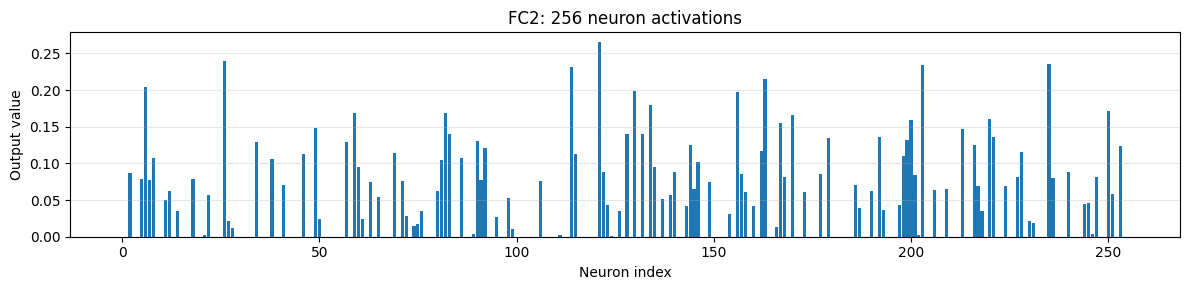


FC3 output (logits)
Shape: (1, 10)
Number of elements: 10
Data type: torch.float32
Min: -0.0887584537267685
Max: 0.0995592549443245
Mean: 0.009494700469076633
Values:
 tensor([[-0.0888, -0.0133,  0.0655,  0.0218, -0.0294, -0.0068,  0.0256,  0.0304,
         -0.0096,  0.0996]])


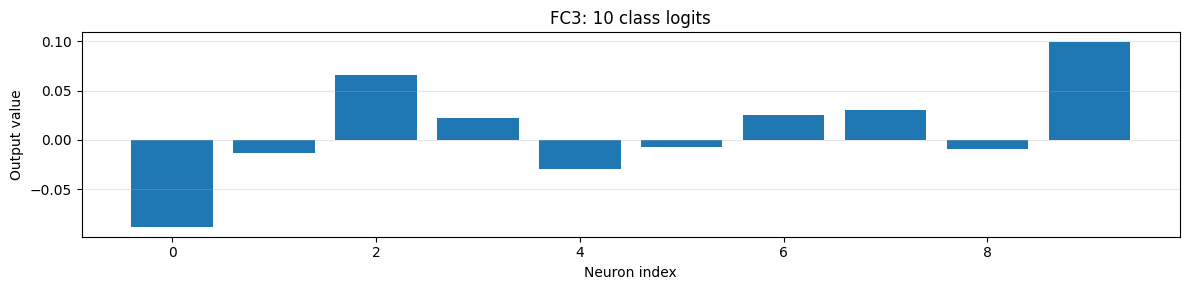


Softmax probabilities
Shape: (1, 10)
Number of elements: 10
Data type: torch.float32
Min: 0.09053153544664383
Max: 0.1092912033200264
Mean: 0.09999999403953552
Values:
 tensor([[0.0905, 0.0976, 0.1056, 0.1011, 0.0961, 0.0983, 0.1015, 0.1020, 0.0980,
         0.1093]])

Ground-truth label: 6
Predicted class: truck
Confidence: 10.93%

############################################################
OUTPUT SHAPE SUMMARY
############################################################
Flatten             : (1, 3072)
FC1_before_ReLU     : (1, 512)
FC1                 : (1, 512)
FC2_before_ReLU     : (1, 256)
FC2                 : (1, 256)
FC3                 : (1, 10)
Softmax             : (1, 10)


In [51]:
# Function to display feature maps
def show_feature_maps(tensor, title, cols=6):
    """
    Input tensor: [1, channels, height, width]
    Display each channel as an individual feature map.
    """

    tensor = tensor.detach().cpu()[0]

    num_maps = tensor.shape[0]
    rows = math.ceil(num_maps / cols)

    fig, axes = plt.subplots(
        rows,
        cols,
        figsize=(cols * 2.2, rows * 2.2),
        squeeze=False
    )

    fig.suptitle(title, fontsize=15)

    for i, ax in enumerate(axes.flat):

        if i < num_maps:
            feature_map = tensor[i].numpy()

            im = ax.imshow(feature_map, cmap="viridis")

            ax.set_title(
                f"Channel {i}\n{feature_map.shape}",
                fontsize=9
            )

            ax.axis("off")
            fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

        else:
            ax.axis("off")

    plt.tight_layout()
    plt.show()

# Function to display neuron activations
def show_neurons(tensor, title):
    """
    Input tensor: [1, number_of_neurons]
    """

    values = tensor.detach().cpu()[0].numpy()

    plt.figure(figsize=(12, 3))

    plt.bar(range(len(values)), values)

    plt.title(title)
    plt.xlabel("Neuron index")
    plt.ylabel("Output value")

    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

# Function to inspect tensor shape and values
def inspect_tensor(name, tensor, show_all=False):
    tensor = tensor.detach().cpu()

    print("\n" + "=" * 65)
    print(name)
    print("=" * 65)

    print("Shape:", tuple(tensor.shape))
    print("Number of elements:", tensor.numel())
    print("Data type:", tensor.dtype)

    print("Min:", tensor.min().item())
    print("Max:", tensor.max().item())
    print("Mean:", tensor.float().mean().item())

    if show_all:
        print("Values:\n", tensor)
    else:
        print("First 12 values:", tensor.flatten()[:12].tolist())

# Inspect weights, kernels and parameter counts
def inspect_parameters(model):

    print("\n" + "#" * 65)
    print("MODEL PARAMETERS")
    print("#" * 65)

    total_params = 0
    total_trainable = 0

    for name, module in model.named_children():

        params = sum(
            p.numel()
            for p in module.parameters(recurse=False)
        )

        trainable = sum(
            p.numel()
            for p in module.parameters(recurse=False)
            if p.requires_grad
        )

        total_params += params
        total_trainable += trainable

        print(f"\nLayer: {name}")
        print("Parameter count:", params)
        print("Trainable parameters:", trainable)

        if isinstance(module, nn.Conv2d):

            print("Weight shape:", tuple(module.weight.shape))
            print("Bias shape:", tuple(module.bias.shape))

            print("Kernel weights:")
            print(module.weight.detach().cpu())

            print("Bias:")
            print(module.bias.detach().cpu())

        elif isinstance(module, nn.Linear):

            print("Weight shape:", tuple(module.weight.shape))
            print("Bias shape:", tuple(module.bias.shape))

            print("Weight matrix (first 3 rows, 8 columns):")
            print(module.weight[:3, :8].detach().cpu())

            print("Bias values:")
            print(module.bias.detach().cpu())

    print("\n" + "-" * 65)
    print("Total parameters:", total_params)
    print("Total trainable parameters:", total_trainable)

# Forward pass: collect every intermediate output
def visualize_mlp(model, image):
    model.eval()

    # Accept either [3, 32, 32] or [1, 3, 32, 32]
    if image.ndim == 3:
        image = image.unsqueeze(0)

    # Use the same device as the model
    device = next(model.parameters()).device
    image = image.to(device)

    activations = {}

    with torch.no_grad():
        # ---------------- Input ----------------
        x = image

        rgb = x[0].detach().cpu() * 0.5 + 0.5
        rgb = rgb.permute(1, 2, 0).clamp(0, 1).numpy()

        plt.figure(figsize=(4, 4))
        plt.imshow(rgb)
        plt.title("Input CIFAR-10 image")
        plt.axis("off")
        plt.show()

        inspect_tensor("Input", x)

        # ---------------- Flatten ----------------
        flat_out = model.flatten(x)
        activations["Flatten"] = flat_out

        inspect_tensor("Flatten output", flat_out)

        # ---------------- FC1 ----------------
        fc1_pre = model.fc1(flat_out)
        fc1_out = model.relu1(fc1_pre)

        activations["FC1_before_ReLU"] = fc1_pre
        activations["FC1"] = fc1_out

        inspect_tensor("FC1 before ReLU", fc1_pre)
        inspect_tensor("FC1 after ReLU", fc1_out)

        show_neurons(fc1_out, "FC1: 512 neuron activations")

        # ---------------- FC2 ----------------
        fc2_pre = model.fc2(fc1_out)
        fc2_out = model.relu2(fc2_pre)

        activations["FC2_before_ReLU"] = fc2_pre
        activations["FC2"] = fc2_out

        inspect_tensor("FC2 before ReLU", fc2_pre)
        inspect_tensor("FC2 after ReLU", fc2_out)

        show_neurons(fc2_out, "FC2: 256 neuron activations")

        # ---------------- FC3 ----------------
        logits = model.fc3(fc2_out)
        activations["FC3"] = logits

        inspect_tensor("FC3 output (logits)", logits, show_all=True)
        show_neurons(logits, "FC3: 10 class logits")

        # ---------------- Softmax ----------------
        probabilities = torch.softmax(logits, dim=1)
        activations["Softmax"] = probabilities

        inspect_tensor(
            "Softmax probabilities",
            probabilities,
            show_all=True
        )

        predicted_class = probabilities.argmax(dim=1).item()

        classes = [
            "airplane", "automobile", "bird", "cat", "deer",
            "dog", "frog", "horse", "ship", "truck"
        ]

        print("\nGround-truth label:", label)
        print("Predicted class:", classes[predicted_class])
        print(
            "Confidence:",
            f"{probabilities[0, predicted_class].item() * 100:.2f}%"
        )

    print("\n" + "#" * 60)
    print("OUTPUT SHAPE SUMMARY")
    print("#" * 60)

    for name, tensor in activations.items():
        print(f"{name:20s}: {tuple(tensor.shape)}")

    return activations

# Load one CIFAR-10 image and run inspection
torch.manual_seed(42)

image, label = trainset[0]

print("Ground-truth class index:", label)

# Batch size = 1
image = image.unsqueeze(0)

# Create a fresh model using the original architecture
model = MLPClassifier()

# Inspect kernel matrices and weights
inspect_parameters(model)

# Visualize all layers
activations = visualize_mlp(model, image)